In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/13H1VTAZ42.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/G0DWU2GK1L.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/CVPHC0DT1P.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/90XJFQDL7G.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/3V8LZ56MOW.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/Y9EUV6TNP2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/K76P42J0GK.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/ZSS7THB1UM.jpg
/kaggle/input/comp

# guide for Milestone 1 

https://manyakaistha.github.io/DLGenAI-26T3/guide_02_spatial_exclusivity_and_output_heads.html

# Question 1: Global Class Distribution & Clean Sample Mass


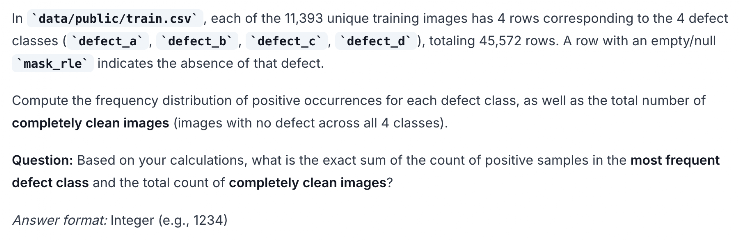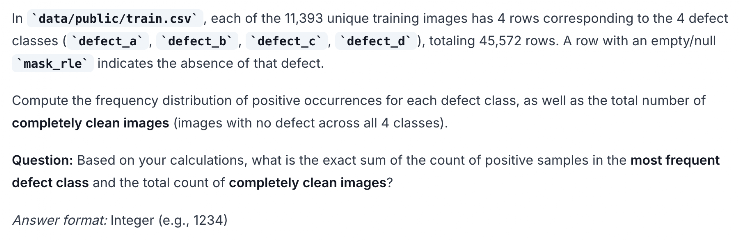

In [3]:
import pandas as pd

df = pd.read_csv("/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")

# Identify positive defect masks
has_mask = ( df["mask_rle"].notna()& df["mask_rle"].astype("string").str.strip().ne(""))

# Count positive samples for each defect class
positive_counts = df.loc[has_mask, "defect_type"].value_counts()
print("Positive samples by class:")
print(positive_counts)

# Count completely clean images
positive_images = df.loc[has_mask, "image_id"].nunique()
total_images = df["image_id"].nunique()
clean_images = total_images - positive_images

# Calculate the answer
answer = int(positive_counts.max()) + int(clean_images)

print("Completely clean images:", clean_images)
print("Final answer:", answer)

Positive samples by class:
defect_type
defect_c    4100
defect_d    1707
defect_a    1081
defect_b     313
Name: count, dtype: int64
Completely clean images: 5516
Final answer: 9616


# Question 2: Multi-Label Cardinality & Co-occurrence Complexity

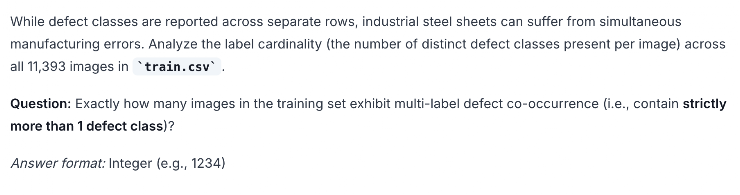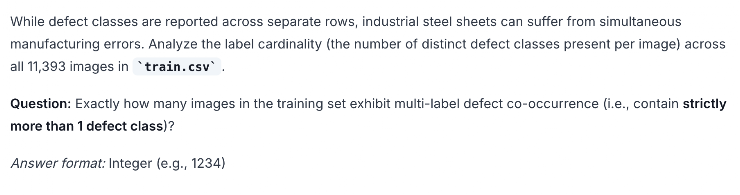

In [4]:
# Keep only positive defect annotations
positive_df = df.loc[has_mask]

# Count distinct defect classes present in each image
labels_per_image = positive_df.groupby("image_id")["defect_type"].nunique()

# Count images containing more than one distinct defect class
multi_label_images = int((labels_per_image > 1).sum())

print("Images with multiple defect classes:", multi_label_images)

Images with multiple defect classes: 1198


# Question 3: The Spatial Mutual-Exclusivity Proof (Architectural Insight)
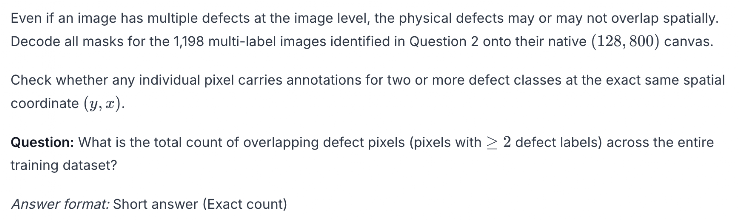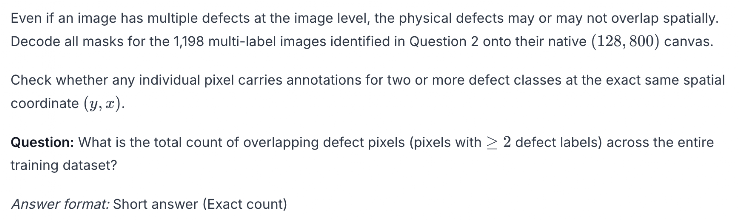

In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv('/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv')

HEIGHT, WIDTH = 128, 800
classes = ["defect_a", "defect_b", "defect_c", "defect_d"]

# Keep only rows with non-empty masks
df["has_mask"] = (df["mask_rle"].notna()& df["mask_rle"].astype("string").str.strip().ne(""))

# Identify images with more than one defect class
positive = df[df["has_mask"]]
label_counts = positive.groupby("image_id")["defect_type"].nunique()
multi_label_ids = label_counts[label_counts > 1].index

print("Multi-label images:", len(multi_label_ids))

total_overlapping_pixels = 0

for image_id in multi_label_ids:
    image_rows = positive[positive["image_id"] == image_id]
    mask_count = np.zeros((HEIGHT, WIDTH), dtype=np.uint8)

    for _, row in image_rows.iterrows():
        rle = row["mask_rle"]
        values = np.asarray(rle.split(), dtype=np.int64)
        starts = values[0::2] - 1
        lengths = values[1::2]

        flat_mask = np.zeros(HEIGHT * WIDTH, dtype=np.uint8)

        for start, length in zip(starts, lengths):
            flat_mask[start:start + length] = 1

        mask = flat_mask.reshape((HEIGHT, WIDTH), order="F")
        mask_count += mask

    # Count pixels belonging to two or more defect classes
    total_overlapping_pixels += int((mask_count >= 2).sum())

print("Total overlapping defect pixels:", total_overlapping_pixels)

Multi-label images: 1198
Total overlapping defect pixels: 0


# Q:4 Run-Length Encoding (RLE) and Memory Layouts 

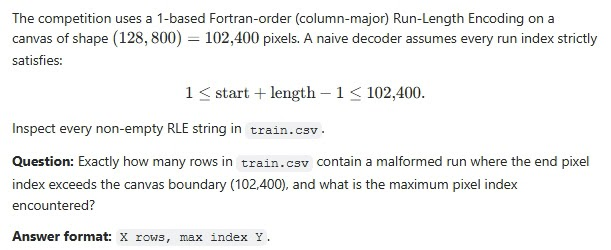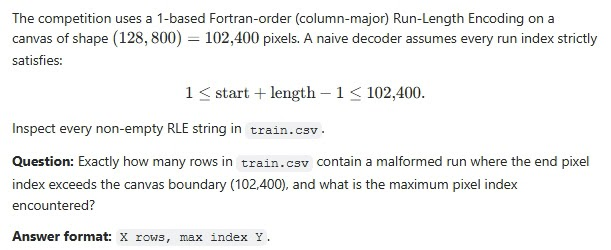

In [7]:
import pandas as pd
import numpy as np



TOTAL_PIXELS = 128 * 800  # 102400

malformed_rows = 0
max_end_index = 0

for rle in df["mask_rle"].dropna():
    rle = str(rle).strip()

    if not rle:
        continue

    values = rle.split()

    # RLE must contain start-length pairs
    if len(values) % 2 != 0:
        raise ValueError(f"Malformed RLE pair count: {rle}")

    values = np.asarray(values, dtype=np.int64)
    starts = values[0::2]
    lengths = values[1::2]

    # 1-based ending pixel index
    end_indices = starts + lengths - 1

    max_end_index = max(max_end_index, int(end_indices.max()))

    # Count each row only once, even if it has multiple invalid runs
    if np.any(end_indices > TOTAL_PIXELS):
        malformed_rows += 1

print(f"{malformed_rows} rows, max index {max_end_index}")

0 rows, max index 102400


# Sensor Aspect Ratios, Line-Scan Cameras, and Aliasing 
# Question 5: Geometric Distortion & Anisotropic Aspect Ratio

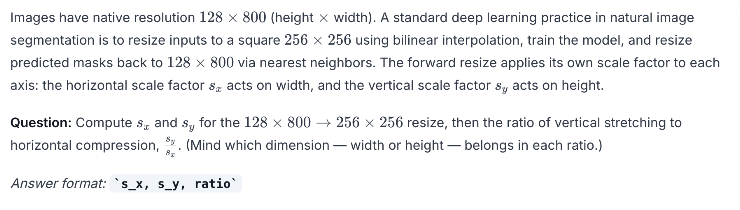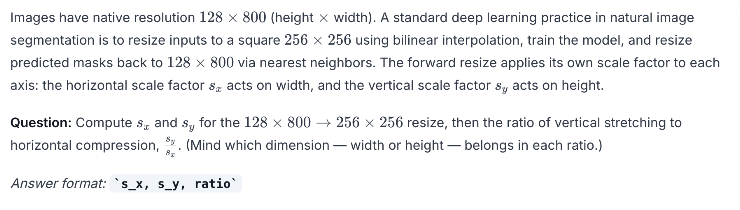

In [8]:
# Original image dimensions
original_height = 128
original_width = 800

# Target square dimensions
target_height = 256
target_width = 256

# Scale factors
s_x = target_width / original_width
s_y = target_height / original_height

# Vertical stretching relative to horizontal stretching
ratio = s_y / s_x

print(f"s_x, s_y, ratio: {s_x:.4f}, {s_y:.4f}, {ratio:.4f}")

s_x, s_y, ratio: 0.3200, 2.0000, 6.2500


# Photometric Separation vs. Pure Texture Anomalies (Cohen's d) 
# Question 6: Photometric Invisibility & Defect Feature Types (Cohen's d)

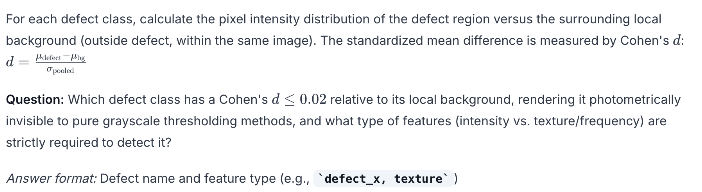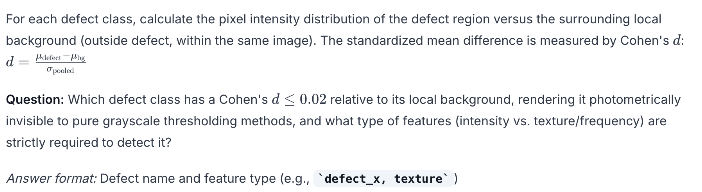

In [11]:
import pandas as pd
import numpy as np
import cv2
from pathlib import Path

# --------------------------------------------------
# 1. Automatically locate the dataset
# --------------------------------------------------
INPUT_ROOT = Path("/kaggle/input")

csv_files = list(INPUT_ROOT.rglob("train.csv"))

if not csv_files:
    raise FileNotFoundError(
        "train.csv not found. Check that the competition dataset "
        "is added to your Kaggle notebook."
    )

# Prefer a CSV whose parent directory contains the train folder
CSV_PATH = next(
    (p for p in csv_files if (p.parent / "train").is_dir()),
    csv_files[0]
)

INPUT_DIR = CSV_PATH.parent
TRAIN_DIR = INPUT_DIR / "train"

print("CSV path:", CSV_PATH)
print("Training image directory:", TRAIN_DIR)

df = pd.read_csv(CSV_PATH)

HEIGHT, WIDTH = 128, 800
DEFECT_CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]


# --------------------------------------------------
# 2. Decode column-major RLE
# --------------------------------------------------
def decode_rle(rle, height=HEIGHT, width=WIDTH):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)

    if len(values) % 2:
        raise ValueError(f"Odd number of RLE values: {rle}")

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        end = start + length

        if start < 0 or length <= 0 or end > height * width:
            raise ValueError(f"Invalid RLE: {rle}")

        mask[start:end] = 1

    return mask.reshape((height, width), order="F")


# --------------------------------------------------
# 3. Calculate Cohen's d
# --------------------------------------------------
def cohens_d(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    if len(a) < 2 or len(b) < 2:
        return np.nan

    pooled_var = (
        (len(a) - 1) * np.var(a, ddof=1)
        + (len(b) - 1) * np.var(b, ddof=1)
    ) / (len(a) + len(b) - 2)

    if pooled_var <= 0:
        return 0.0 if np.mean(a) == np.mean(b) else np.nan

    return (np.mean(a) - np.mean(b)) / np.sqrt(pooled_var)


# --------------------------------------------------
# 4. Analyze defect intensity vs local background
# --------------------------------------------------
results = []

for defect in DEFECT_CLASSES:
    class_rows = df[
        (df["defect_type"] == defect)
        & df["mask_rle"].notna()
        & df["mask_rle"].astype("string").str.strip().ne("")
    ]

    effect_sizes = []
    texture_differences = []
    missing_images = 0

    for _, row in class_rows.iterrows():
        image_id = str(row["image_id"])

        # Support image IDs both with and without .jpg
        candidates = [
            TRAIN_DIR / image_id,
            TRAIN_DIR / f"{image_id}.jpg"
        ]

        image_path = next((p for p in candidates if p.is_file()), None)

        if image_path is None:
            missing_images += 1
            continue

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

        if image is None:
            missing_images += 1
            continue

        if image.shape != (HEIGHT, WIDTH):
            raise ValueError(
                f"Unexpected image dimensions for {image_id}: {image.shape}"
            )

        mask = decode_rle(row["mask_rle"]).astype(bool)

        if mask.sum() < 2 or (~mask).sum() < 2:
            continue

        # Local background outside a 9x9 dilation of the defect
        kernel = np.ones((9, 9), dtype=np.uint8)
        dilated = cv2.dilate(mask.astype(np.uint8), kernel).astype(bool)
        background_mask = dilated & ~mask

        if background_mask.sum() < 2:
            continue

        defect_pixels = image[mask].astype(np.float64)
        background_pixels = image[background_mask].astype(np.float64)

        d = cohens_d(defect_pixels, background_pixels)

        if np.isfinite(d):
            effect_sizes.append(abs(d))
            texture_differences.append(
                abs(np.std(defect_pixels) - np.std(background_pixels))
            )

    results.append({
        "defect_type": defect,
        "images_evaluated": len(effect_sizes),
        "missing_images": missing_images,
        "mean_absolute_cohens_d": (
            np.mean(effect_sizes) if effect_sizes else np.nan
        ),
        "mean_texture_difference": (
            np.mean(texture_differences) if texture_differences else np.nan
        )
    })

results_df = pd.DataFrame(results)

print("\nIntensity and texture analysis:")
print(results_df.to_string(index=False))


# --------------------------------------------------
# 5. Identify the weakest intensity contrast
# --------------------------------------------------
valid = results_df.dropna(subset=["mean_absolute_cohens_d"])

if valid.empty:
    print("\nNo valid Cohen's d estimates were obtained.")
else:
    weakest = valid.loc[valid["mean_absolute_cohens_d"].idxmin()]

    print("\nWeakest intensity contrast:")
    print("Defect class:", weakest["defect_type"])
    print(
        "Mean absolute Cohen's d:",
        f"{weakest['mean_absolute_cohens_d']:.6f}"
    )

    if weakest["mean_absolute_cohens_d"] <= 0.02:
        print(
            "Answer:",
            f"{weakest['defect_type']}, texture/frequency"
        )
    else:
        print(
            "No defect class meets the absolute Cohen's d <= 0.02 "
            "threshold using this aggregation method."
        )

CSV path: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
Training image directory: /kaggle/input/competitions/industrial-surface-defect-detection/public/train

Intensity and texture analysis:
defect_type  images_evaluated  missing_images  mean_absolute_cohens_d  mean_texture_difference
   defect_a              1081               0                0.327627                 6.236493
   defect_b               313               0                0.313946                 3.222887
   defect_c              4100               0                0.409193                 9.429889
   defect_d              1707               0                0.459392                 6.438714

Weakest intensity contrast:
Defect class: defect_b
Mean absolute Cohen's d: 0.313946
No defect class meets the absolute Cohen's d <= 0.02 threshold using this aggregation method.


In [ ]:
import numpy as np
import pandas as pd
import cv2

HEIGHT, WIDTH = 128, 800
classes = ["defect_a", "defect_b", "defect_c", "defect_d"]

results = []

for defect in classes:
    rows = df[
        (df["defect_type"] == defect)
        & df["mask_rle"].notna()
        & df["mask_rle"].astype("string").str.strip().ne("")
    ]

    defect_values = []
    background_values = []

    for _, row in rows.iterrows():
        image_id = str(row["image_id"])
        candidates = [
            TRAIN_DIR / image_id,
            TRAIN_DIR / f"{image_id}.jpg"
        ]
        image_path = next((p for p in candidates if p.is_file()), None)

        if image_path is None:
            continue

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if image is None or image.shape != (HEIGHT, WIDTH):
            continue

        mask = decode_rle(row["mask_rle"]).astype(bool)

        if mask.sum() == 0:
            continue

        # Define a local background around the defect
        kernel = np.ones((9, 9), dtype=np.uint8)
        dilated = cv2.dilate(mask.astype(np.uint8), kernel).astype(bool)
        background_mask = dilated & ~mask

        if background_mask.sum() == 0:
            continue

        defect_values.extend(image[mask].astype(np.float32))
        background_values.extend(image[background_mask].astype(np.float32))

    a = np.asarray(defect_values, dtype=np.float64)
    b = np.asarray(background_values, dtype=np.float64)

    if len(a) < 2 or len(b) < 2:
        d = np.nan
    else:
        pooled_var = (
            (len(a) - 1) * np.var(a, ddof=1)
            + (len(b) - 1) * np.var(b, ddof=1)
        ) / (len(a) + len(b) - 2)

        d = (
            (a.mean() - b.mean()) / np.sqrt(pooled_var)
            if pooled_var > 0 else np.nan
        )

    results.append({
        "defect_type": defect,
        "pooled_cohens_d": d,
        "absolute_d": abs(d) if np.isfinite(d) else np.nan
    })

result_df = pd.DataFrame(results)
print(result_df.to_string(index=False))

valid = result_df.dropna(subset=["absolute_d"])

if not valid.empty:
    weakest = valid.loc[valid["absolute_d"].idxmin()]
    print("\nWeakest class:", weakest["defect_type"])
    print("Absolute Cohen's d:", weakest["absolute_d"])

    if weakest["absolute_d"] <= 0.02:
        print(f"Answer: {weakest['defect_type']}, texture/frequency")
    else:
        print("No class meets the specified threshold.")

# The Sørensen–Dice Index and Negative Step Functions (Concepts for Q7)

# Question 7: Metric Behavior — The Discontinuous Step Function of Naive Dice


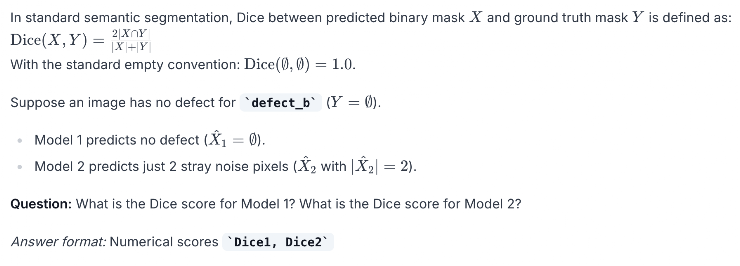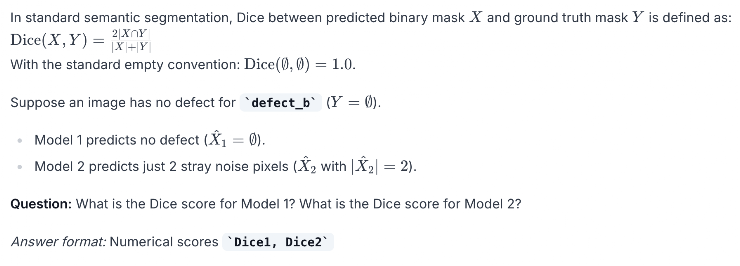

In [12]:
# Dice score for empty ground-truth masks

def dice_score(predicted_pixels, ground_truth_pixels):
    if predicted_pixels + ground_truth_pixels == 0:
        return 1.0

    return (2 * min(predicted_pixels, ground_truth_pixels)) / (
        predicted_pixels + ground_truth_pixels
    )

# Ground truth has no defect
ground_truth = 0

# Model 1 predicts no defect
model1_prediction = 0
dice1 = dice_score(model1_prediction, ground_truth)

# Model 2 predicts 2 stray pixels
model2_prediction = 2
dice2 = dice_score(model2_prediction, ground_truth)

print(f"{dice1:.1f}, {dice2:.1f}")


1.0, 0.0


# The Competition Scorer and The "All-Empty Baseline Paradox" (Concepts for Q8 & Q9)

# Question 8: Official Competition Weighted Metric — Toy Batch Calculation



In [13]:
# Validation set statistics
total_pairs = 50

positive_pairs = 10
dice_080_count = 6
dice_040_count = 4

empty_pairs = 40
correct_empty_predictions = 36
false_positive_pairs = 4
false_positive_pixels_each = 1024

total_pixels = 102400

# (a) Foreground Dice: average only over positive pairs
foreground_dice = (
    0.80 * dice_080_count + 0.40 * dice_040_count
) / positive_pairs

# (b) False Positive Score
mean_fp_pixel_fraction = (
    false_positive_pairs * false_positive_pixels_each
    / (empty_pairs * total_pixels)
)
false_positive_score = 1 - mean_fp_pixel_fraction

# (c) Empty Accuracy
empty_accuracy = correct_empty_predictions / empty_pairs

# (d) Final weighted score
final_score = (
    0.70 * foreground_dice
    + 0.20 * false_positive_score
    + 0.10 * empty_accuracy
)

print(
    f"{foreground_dice:.4f}, "
    f"{false_positive_score:.4f}, "
    f"{empty_accuracy:.4f}, "
    f"{final_score:.4f}"
)

0.6400, 0.9990, 0.9000, 0.7378


# Q:9 

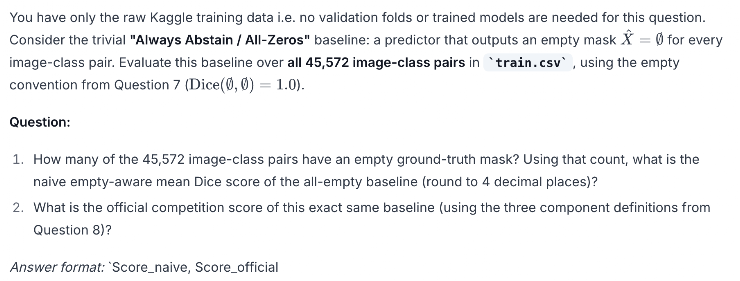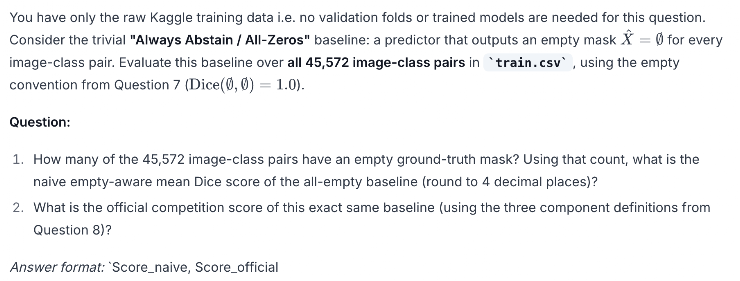

In [14]:
import pandas as pd
import numpy as np
from pathlib import Path

# Find train.csv automatically
csv_files = list(Path("/kaggle/input").rglob("train.csv"))

if not csv_files:
    raise FileNotFoundError("Could not find train.csv in /kaggle/input")

CSV_PATH = next(
    (p for p in csv_files if len(pd.read_csv(p, nrows=0).columns) >= 3),
    csv_files[0]
)

df = pd.read_csv(CSV_PATH)

TOTAL_PAIRS = len(df)
TOTAL_PIXELS = 128 * 800

# Empty ground-truth mask = missing, null, or blank RLE
has_mask = (
    df["mask_rle"].notna()
    & df["mask_rle"].astype("string").str.strip().ne("")
)

positive_pairs = int(has_mask.sum())
empty_pairs = TOTAL_PAIRS - positive_pairs

# 1. Naive all-empty baseline:
# Dice = 1 for empty ground truth, 0 for positive ground truth
score_naive = empty_pairs / TOTAL_PAIRS

# 2. Official competition score
# ForegroundDice: average only over positive ground-truth pairs.
# All-zero predictions have Dice = 0 for every positive pair.
foreground_dice = 0.0

# FalsePositiveScore: no false-positive pixels are predicted.
false_positive_score = 1.0

# EmptyAccuracy: every empty ground-truth pair is predicted empty.
empty_accuracy = 1.0

score_official = (
    0.70 * foreground_dice
    + 0.20 * false_positive_score
    + 0.10 * empty_accuracy
)

print("Total image-class pairs:", TOTAL_PAIRS)
print("Positive ground-truth pairs:", positive_pairs)
print("Empty ground-truth pairs:", empty_pairs)
print(f"Naive all-empty Dice score: {score_naive:.4f}")
print(f"Official competition score: {score_official:.4f}")
print(f"{score_naive:.4f}, {score_official:.4f}")

Total image-class pairs: 45572
Positive ground-truth pairs: 7201
Empty ground-truth pairs: 38371
Naive all-empty Dice score: 0.8420
Official competition score: 0.3000
0.8420, 0.3000


# Morphological Post-Processing, Connected Components, and Recall Ceilings 

# Question 10: Morphological Noise Filtering — Minimum Area Recall Ceilings


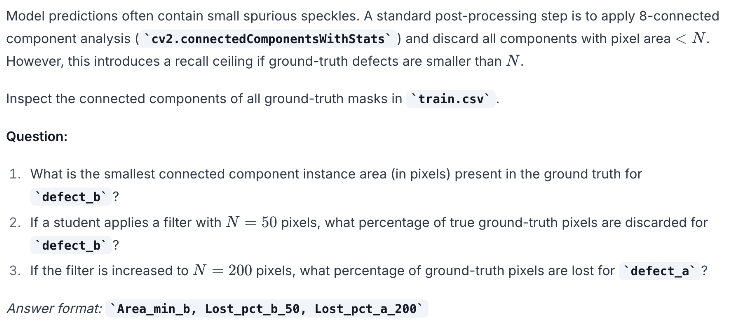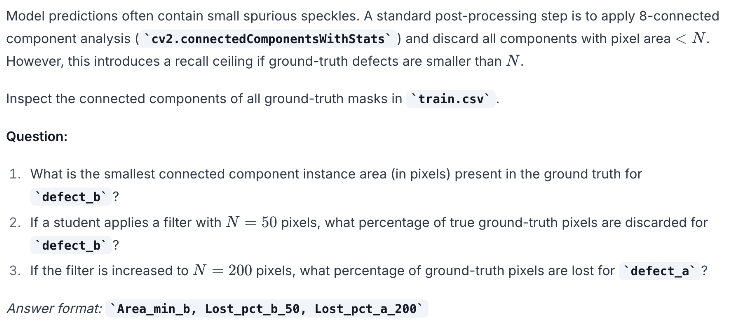

In [15]:
import pandas as pd
import numpy as np
import cv2
from pathlib import Path

# Find train.csv automatically
csv_files = list(Path("/kaggle/input").rglob("train.csv"))

if not csv_files:
    raise FileNotFoundError("train.csv not found in /kaggle/input")

CSV_PATH = csv_files[0]
df = pd.read_csv(CSV_PATH)

HEIGHT, WIDTH = 128, 800


def decode_rle(rle):
    """Decode 1-based, column-major RLE."""
    flat = np.zeros(HEIGHT * WIDTH, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return flat.reshape((HEIGHT, WIDTH), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)

    if len(values) % 2:
        raise ValueError(f"Malformed RLE: {rle}")

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        end = start + length
        if start < 0 or length <= 0 or end > HEIGHT * WIDTH:
            raise ValueError(f"Invalid RLE: {rle}")
        flat[start:end] = 1

    return flat.reshape((HEIGHT, WIDTH), order="F")


def get_component_areas(mask):
    """Return areas of all 8-connected foreground components."""
    count, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8),
        connectivity=8
    )

    # Component 0 is the background
    return stats[1:, cv2.CC_STAT_AREA]


def analyze_class(defect_type):
    rows = df[df["defect_type"] == defect_type]

    component_areas = []
    total_defect_pixels = 0

    for rle in rows["mask_rle"]:
        mask = decode_rle(rle)
        total_defect_pixels += int(mask.sum())

        areas = get_component_areas(mask)
        component_areas.extend(areas.tolist())

    return np.asarray(component_areas, dtype=np.int64), total_defect_pixels


# --------------------------------------------------
# 1. Smallest component area for defect_b
# --------------------------------------------------
areas_b, pixels_b = analyze_class("defect_b")

if len(areas_b) == 0:
    raise ValueError("No connected components found for defect_b")

area_min_b = int(areas_b.min())


# --------------------------------------------------
# 2. Percentage of defect_b pixels lost at N = 50
# --------------------------------------------------
lost_pixels_b_50 = int(areas_b[areas_b < 50].sum())

lost_pct_b_50 = (
    100.0 * lost_pixels_b_50 / pixels_b
    if pixels_b > 0 else 0.0
)


# --------------------------------------------------
# 3. Percentage of defect_a pixels lost at N = 200
# --------------------------------------------------
areas_a, pixels_a = analyze_class("defect_a")

lost_pixels_a_200 = int(areas_a[areas_a < 200].sum())

lost_pct_a_200 = (
    100.0 * lost_pixels_a_200 / pixels_a
    if pixels_a > 0 else 0.0
)


# --------------------------------------------------
# Print requested answer
# --------------------------------------------------
print("Minimum defect_b component area:", area_min_b)
print(f"defect_b pixel loss at N=50: {lost_pct_b_50:.6f}%")
print(f"defect_a pixel loss at N=200: {lost_pct_a_200:.6f}%")

print(
    f"{area_min_b}, "
    f"{lost_pct_b_50:.4f}, "
    f"{lost_pct_a_200:.4f}"
)

Minimum defect_b component area: 93
defect_b pixel loss at N=50: 0.000000%
defect_a pixel loss at N=200: 15.217053%
93, 0.0000, 15.2171


# Q:11

In [2]:
!pip install -q segmentation-models-pytorch

from pathlib import Path
import random

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

DATA_ROOT = Path("data/public")  # EDIT for Kaggle or your local environment.
OUTPUT_DIR = Path("runs/milestone_1_starter")
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800
VAL_FRACTION = 0.20
SEED = 42
EPOCHS = 5  # Question 12: use 5–10 epochs.
BATCH_SIZE = 8
ENCODER = "resnet34"  # Alternative: "efficientnet-b0".
ENCODER_WEIGHTS = "imagenet"
THRESHOLDS = [0.3, 0.5, 0.7, 0.9]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.6 MB/s eta 0:00:0000:01
Device: cpu


In [6]:
annotations = pd.read_csv("/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv", dtype=str, keep_default_na=False)
required = {"image_id", "defect_type", "mask_rle", "height", "width"}
if not required.issubset(annotations.columns):
    raise ValueError(f"Missing CSV columns: {required - set(annotations.columns)}")
if set(annotations["defect_type"]) != set(CLASSES):
    raise ValueError("Unexpected defect classes")
if annotations.duplicated(["image_id", "defect_type"]).any():
    raise ValueError("Duplicate image–class rows")
if not (annotations.groupby("image_id").size() == len(CLASSES)).all():
    raise ValueError("Every image must have one row for each of the four classes")
if not ((annotations["height"].astype(int) == HEIGHT)
        & (annotations["width"].astype(int) == WIDTH)).all():
    raise ValueError("Expected native height=128 and width=800")

annotations["mask_rle"] = annotations["mask_rle"].str.strip()
rle_table = annotations.pivot(
    index="image_id", columns="defect_type", values="mask_rle"
).reindex(columns=CLASSES).sort_index()
presence = rle_table.ne("")  # Boolean image × class table.


def combination_string(row):
    active_classes = [name for name in CLASSES if row[name]]
    return "+".join(active_classes) if active_classes else "clean"


image_table = presence.copy()
image_table["label_combo"] = presence.apply(combination_string, axis=1)
combination_counts = image_table["label_combo"].value_counts().sort_index()


In [7]:
n_combos = int(image_table["label_combo"].nunique())

# Count defect_b-positive images
b_positive_count = int(presence["defect_b"].sum())

# Ideal 20% validation count, rounded once
b_in_val_ideal = round(0.20 * b_positive_count)

print(f"n_combos: {n_combos}")
print(f"b_positive_count: {b_positive_count}")
print(f"b_in_val_ideal: {b_in_val_ideal}")

n_combos: 15
b_positive_count: 313
b_in_val_ideal: 63


In [8]:
if combination_counts.min() < 2:
    rare = combination_counts[combination_counts < 2]
    raise ValueError(f"Singleton combinations need an explicit split policy:\n{rare}")
train_ids, val_ids = train_test_split(
    image_table.index.to_numpy(),
    test_size=VAL_FRACTION,
    random_state=SEED,
    stratify=image_table["label_combo"].to_numpy(),
)
assert not set(train_ids) & set(val_ids)
assert set(train_ids) | set(val_ids) == set(image_table.index)

split_table = image_table[["label_combo"]].copy()
split_table["partition"] = "train"
split_table.loc[val_ids, "partition"] = "validation"
split_table.to_csv(OUTPUT_DIR / "holdout.csv", index_label="image_id")
print("Train images:", len(train_ids), "Validation images:", len(val_ids))

Train images: 9114 Validation images: 2279


# Question 12: Decode targets and load image–mask pairs

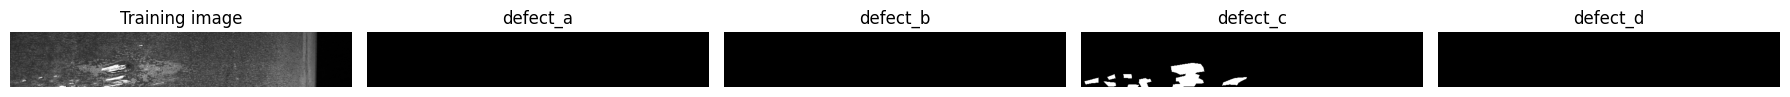

In [9]:
def decode_rle(rle):
    flat = np.zeros(HEIGHT * WIDTH, dtype=np.float32)
    if not str(rle).strip():
        return flat.reshape(HEIGHT, WIDTH, order="F")
    tokens = np.asarray(str(rle).split(), dtype=np.int64)
    if len(tokens) % 2:
        raise ValueError("RLE needs start/length pairs")
    starts, lengths = tokens[0::2] - 1, tokens[1::2]
    ends = starts + lengths
    if np.any(starts < 0) or np.any(starts >= flat.size) or np.any(lengths <= 0):
        raise ValueError("Invalid RLE start or length")
    if np.any(starts[1:] < ends[:-1]):
        raise ValueError("Unsorted or overlapping runs in one mask")
    for start, end in zip(starts, np.minimum(ends, flat.size)):
        flat[start:end] = 1.0
    return flat.reshape(HEIGHT, WIDTH, order="F")


class SurfaceDataset(Dataset):
    def __init__(self, image_ids, rle_table, data_root):
        self.image_ids = list(image_ids)
        self.rle_table = rle_table
        self.data_root = Path(data_root)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        filename = image_id if image_id.endswith(".jpg") else image_id + ".jpg"
        with Image.open(self.data_root / "train" / filename) as handle:
            image = np.asarray(handle.convert("L"), dtype=np.float32) / 255.0
        if image.shape != (HEIGHT, WIDTH):
            raise ValueError(f"Wrong image shape for {image_id}: {image.shape}")
        # Normalize independently per image; train and validation use the same rule.
        image = (image - image.mean()) / max(float(image.std()), 0.05)
        masks = np.stack([decode_rle(self.rle_table.loc[image_id, c]) for c in CLASSES])
        return torch.from_numpy(image[None].copy()), torch.from_numpy(masks.copy())

# Updated DATA_ROOT to match Kaggle input path
KAGGLE_DATA_ROOT = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
train_dataset = SurfaceDataset(train_ids, rle_table, KAGGLE_DATA_ROOT)
val_dataset = SurfaceDataset(val_ids, rle_table, KAGGLE_DATA_ROOT)
# workers=0 works in notebooks and on macOS without multiprocessing setup.
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    pin_memory=DEVICE.type == "cuda", generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
image, masks = train_dataset[0]
assert image.shape == (1, HEIGHT, WIDTH)
assert masks.shape == (len(CLASSES), HEIGHT, WIDTH)
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
axes[0].imshow(image[0], cmap="gray")
axes[0].set_title("Training image")
for c, axis in enumerate(axes[1:]):
    axis.imshow(masks[c], cmap="gray", vmin=0, vmax=1)
    axis.set_title(CLASSES[c])
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## Baseline model and loss
Q12 asks for sigmoid probabilities. Use four independent output channels;
the model returns logits, and the loss applies sigmoid where appropriate.
BCE supplies supervision on both positive and empty targets. The Dice term
averages over nonempty image–class targets. No area filtering is used.


In [10]:
model = smp.Unet(
    encoder_name=ENCODER, encoder_weights=ENCODER_WEIGHTS,
    in_channels=1, classes=len(CLASSES), activation=None,
).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(logits, targets):
    bce = bce_loss(logits, targets)
    probs = logits.sigmoid()
    intersection = (probs * targets).sum(dim=(-2, -1))
    denominator = probs.sum(dim=(-2, -1)) + targets.sum(dim=(-2, -1))
    soft_dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
    positive = (targets.sum(dim=(-2, -1)) > 0).to(logits.dtype)
    dice_loss = ((1 - soft_dice) * positive).sum() / positive.sum().clamp_min(1)
    return 0.5 * bce + 0.5 * dice_loss


@torch.no_grad()
def validation_loss(model, loader):
    model.eval()
    total, samples = 0.0, 0
    for images, targets in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        loss = segmentation_loss(model(images), targets)
        total += loss.item() * len(images)
        samples += len(images)
    return total / samples


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

## Train for 5–10 epochs
Execute this cell when ready to start the full experiment. It saves the model
with the lowest validation loss. The threshold sweep uses that same checkpoint
for every threshold. Validation loss is a checkpoint criterion, not the Q8 score.


In [ ]:
history = []
best_val_loss = float("inf")
checkpoint_path = OUTPUT_DIR / "best.pt"
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, samples = 0.0, 0
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")
    for images, targets in progress:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = segmentation_loss(model(images), targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(images)
        samples += len(images)
        progress.set_postfix(loss=running_loss / samples)
    val_loss = validation_loss(model, val_loader)
    history.append({"epoch": epoch, "train_loss": running_loss / samples, "val_loss": val_loss})
    print(history[-1])
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)
pd.DataFrame(history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))


Epoch 1/5:   0%|          | 0/1140 [00:00<?, ?it/s]

## Threshold sweep on the complete validation holdout
Accumulate sufficient statistics instead of storing all probability maps.
Each image–class pair contributes equally to its relevant component average.
The assessment_score below implements the explicit definitions in Question 8;
it does not claim to reproduce an unpublished leaderboard implementation.
Two false-positive measures are recorded: false pixels / canvas pixels on
empty pairs, and the proportion of empty pairs with any predicted foreground.


In [ ]:
@torch.no_grad()
def threshold_sweep(model, loader, thresholds):
    model.eval()
    totals = {tau: dict(pairs=0, positive=0, empty=0, dice_sum=0.0,
                       fg_dice_sum=0.0, fp_fraction_sum=0.0, correct_empty=0)
              for tau in thresholds}
    for images, targets in tqdm(loader, desc="Validation threshold sweep"):
        probs = model(images.to(DEVICE)).sigmoid()
        truth = targets.to(DEVICE) > 0.5
        gt_pixels = truth.sum(dim=(-2, -1))
        positive, empty = gt_pixels > 0, gt_pixels == 0
        for tau in thresholds:
            prediction = probs >= tau  # Raw probabilities; no component/area filtering.
            pred_pixels = prediction.sum(dim=(-2, -1))
            intersection = (prediction & truth).sum(dim=(-2, -1))
            denominator = pred_pixels + gt_pixels
            dice = torch.where(
                denominator == 0, torch.ones_like(denominator, dtype=torch.float32),
                2.0 * intersection / denominator.clamp_min(1),
            )
            total = totals[tau]
            total["pairs"] += truth.shape[0] * truth.shape[1]
            total["positive"] += int(positive.sum().item())
            total["empty"] += int(empty.sum().item())
            total["dice_sum"] += dice.sum().item()
            total["fg_dice_sum"] += dice[positive].sum().item()
            total["fp_fraction_sum"] += (pred_pixels[empty].float() / (HEIGHT * WIDTH)).sum().item()
            total["correct_empty"] += int((empty & (pred_pixels == 0)).sum().item())
    rows = []
    for tau, total in totals.items():
        if not total["positive"] or not total["empty"]:
            raise ValueError("The holdout needs both positive and empty image–class pairs")
        fg = total["fg_dice_sum"] / total["positive"]
        fp_fraction = total["fp_fraction_sum"] / total["empty"]
        empty_accuracy = total["correct_empty"] / total["empty"]
        rows.append({
            "threshold": tau,
            "naive_dice": total["dice_sum"] / total["pairs"],
            "foreground_dice": fg,
            "fp_pixel_fraction": fp_fraction,
            "fp_pair_rate": 1 - empty_accuracy,
            "false_positive_score": 1 - fp_fraction,
            "empty_accuracy": empty_accuracy,
            "assessment_score": 0.70 * fg + 0.20 * (1 - fp_fraction) + 0.10 * empty_accuracy,
            "holdout_empty_pair_fraction": total["empty"] / total["pairs"],
        })
    return pd.DataFrame(rows).sort_values("threshold")


results = threshold_sweep(model, val_loader, THRESHOLDS)
results.to_csv(OUTPUT_DIR / "threshold_sweep.csv", index=False)
print(results.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for metric in ["naive_dice", "foreground_dice", "assessment_score"]:
    axes[0].plot(results["threshold"], results[metric], marker="o", label=metric)
axes[0].set_ylabel("Score")
axes[1].plot(results["threshold"], results["fp_pair_rate"], marker="o")
axes[1].set_ylabel("Empty pairs with any false positive (fraction)")
axes[2].plot(results["threshold"], results["fp_pixel_fraction"], marker="o")
axes[2].set_ylabel("Mean false-positive pixel fraction on empty pairs")
for axis in axes:
    axis.set_xlabel("Decision threshold")
    axis.set_xticks(THRESHOLDS)
    axis.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "threshold_sweep.png", dpi=160)
plt.show()


## TODO: Write your Question 12 answer in bullet points
- Record the model, seed, epochs, checkpoint selection and actual holdout size.
- Describe the observed false-positive and Foreground Dice trends. Distinguish
  a monotonic threshold property from the measured behavior of Dice.
- Identify the peak threshold for each of the two aggregate scores. If several
  thresholds tie, report the tie. Your experiment may produce coincident peaks.
- Connect the difference (or lack of one) to the measured empty-pair fraction.
- Explain any weak foreground performance using examples or per-class inspection.

Resources: https://smp.readthedocs.io/en/latest/models.html
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
https://docs.pytorch.org/docs/stable/data.html
